In [1]:
import re
import json
import statistics

# 1. SIMULATED RAW OCR TEXT FROM MONTHLY UTILITY BILLS
raw_bills = [
    "Bill_ID: B101 | Month: Jan | Usage: 1200 kWh | Rate: $0.15 | Total: $180.00",
    "Bill_ID: B102 | Month: Feb | Usage: 1250 kWh | Rate: $0.15 | Total: $187.50",
    "Bill_ID: B103 | Month: Mar | Usage: 1180 kWh | Rate: $0.15 | Total: $177.00",
    "Bill_ID: B104 | Month: Apr | Usage: 1220 kWh | Rate: $0.15 | Total: $183.00",
    "Bill_ID: B105 | Month: May | Usage: 4800 kWh | Rate: $0.15 | Total: $720.00",  # Usage spike
    "Bill_ID: B106 | Month: Jun | Usage: 1210 kWh | Rate: $0.15 | Total: $290.00",  # Math error
]

# 2. EXTRACTION FUNCTION (Simulating Document Parsing)
def extract_bill_data(raw_text):
    pattern = r"Bill_ID:\s*(\w+)\s*\|\s*Month:\s*(\w+)\s*\|\s*Usage:\s*(\d+)\s*kWh\s*\|\s*Rate:\s*\$([\d.]+)\s*\|\s*Total:\s*\$([\d.]+)"
    match = re.search(pattern, raw_text)
    if not match:
        return {"status": "PARSE_FAILED", "raw": raw_text}

    return {
        "bill_id": match.group(1),
        "month": match.group(2),
        "usage_kwh": float(match.group(3)),
        "rate": float(match.group(4)),
        "billed_total": float(match.group(5))
    }

# 3. VALIDATION & ANOMALY DETECTION PIPELINE
def audit_bills(raw_list):
    parsed_bills = [extract_bill_data(b) for b in raw_list]

    # Calculate historical baseline from first 4 normal months
    baseline_totals = [b["billed_total"] for b in parsed_bills[:4]]
    mean_cost = statistics.mean(baseline_totals)
    stdev_cost = statistics.stdev(baseline_totals)

    audit_results = []

    for bill in parsed_bills:
        flags = []

        # Check 1: Math consistency (Usage * Rate vs Billed Total)
        expected_total = round(bill["usage_kwh"] * bill["rate"], 2)
        if abs(expected_total - bill["billed_total"]) > 0.50:
            flags.append(f"MATH_MISMATCH (Expected ${expected_total}, Billed ${bill['billed_total']})")

        # Check 2: Statistical spike detection (Z-score > 3)
        z_score = (bill["billed_total"] - mean_cost) / stdev_cost
        if z_score > 3.0:
            flags.append(f"COST_SPIKE_ANOMALY (Z-score: {round(z_score, 1)})")

        bill["status"] = "FLAGGED" if flags else "APPROVED"
        bill["audit_flags"] = flags
        audit_results.append(bill)

    return audit_results

# 4. RUN PIPELINE AND PRINT JSON OUTPUT
results = audit_bills(raw_bills)
print(json.dumps(results[-4:], indent=3))

[
   {
      "bill_id": "B103",
      "month": "Mar",
      "usage_kwh": 1180.0,
      "rate": 0.15,
      "billed_total": 177.0,
      "status": "APPROVED",
      "audit_flags": []
   },
   {
      "bill_id": "B104",
      "month": "Apr",
      "usage_kwh": 1220.0,
      "rate": 0.15,
      "billed_total": 183.0,
      "status": "APPROVED",
      "audit_flags": []
   },
   {
      "bill_id": "B105",
      "month": "May",
      "usage_kwh": 4800.0,
      "rate": 0.15,
      "billed_total": 720.0,
      "status": "FLAGGED",
      "audit_flags": [
         "COST_SPIKE_ANOMALY (Z-score: 120.1)"
      ]
   },
   {
      "bill_id": "B106",
      "month": "Jun",
      "usage_kwh": 1210.0,
      "rate": 0.15,
      "billed_total": 290.0,
      "status": "FLAGGED",
      "audit_flags": [
         "MATH_MISMATCH (Expected $181.5, Billed $290.0)",
         "COST_SPIKE_ANOMALY (Z-score: 24.1)"
      ]
   }
]


In [2]:
!pip install pandas numpy scikit-learn


In [4]:
import json
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

# 1. MESSY, UNSTRUCTURED TEXT (Simulating raw PDF OCR from different utility companies)
messy_documents = [
    "PACIFIC GAS & ELECTRIC | Statement Date: 2026-01-15 | Meter #8841 | Total Energy Used: 1,150 kWh | Rate/kWh: 0.16 | Amount Due: $184.00",
    "PG&E Monthly Invoice - Billing Cycle: 2026-02-15 - Consumed 1,210 kWh at $0.16/unit. Total Payable = $193.60",
    "Statement 2026-03-15 | Customer Account 8841 | Usage recorded: 1280 kWh | Unit Price: $0.16 | Balance Due: $204.80",
    "PG&E Bill (2026-04-15) -> Electricity: 1,340 kWh @ $0.16 -> Total Billed: $214.40",
    "Invoice Date: 2026-05-15 | Usage: 1410 kWh | Rate: 0.16 | Please pay $225.60",
    "Billing Date: 2026-06-15 | Total kWh: 1,490 | Rate: $0.16 | Final Amount: $238.40"
]

# 2. LLM STRUCTURED EXTRACTION PROMPT (Template you would pass to Gemini / OpenAI API)
LLM_EXTRACTION_PROMPT = """
Extract the following fields from the raw utility bill text and return ONLY valid JSON:
{
  "billing_date": "YYYY-MM-DD",
  "usage_kwh": float,
  "rate_per_kwh": float,
  "total_billed": float
}
"""

# Simulated LLM structured output (In production, replace this list with your API call response)
structured_records = [
    {"billing_date": "2026-01-15", "usage_kwh": 1150.0, "rate_per_kwh": 0.16, "total_billed": 184.00},
    {"billing_date": "2026-02-15", "usage_kwh": 1210.0, "rate_per_kwh": 0.16, "total_billed": 193.60},
    {"billing_date": "2026-03-15", "usage_kwh": 1280.0, "rate_per_kwh": 0.16, "total_billed": 204.80},
    {"billing_date": "2026-04-15", "usage_kwh": 1340.0, "rate_per_kwh": 0.16, "total_billed": 214.40},
    {"billing_date": "2026-05-15", "usage_kwh": 1410.0, "rate_per_kwh": 0.16, "total_billed": 225.60},
    {"billing_date": "2026-06-15", "usage_kwh": 1490.0, "rate_per_kwh": 0.16, "total_billed": 238.40}
]

# 3. TIME-SERIES FORECASTING & BUDGET ALERT ENGINE
def forecast_next_bill(records):
    df = pd.DataFrame(records)
    df["month_index"] = np.arange(1, len(df) + 1)

    # Train a regression model on historical monthly trend
    X = df[["month_index"]]
    y = df["total_billed"]

    model = LinearRegression()
    model.fit(X, y)

    # Predict Month 7 (July 2026)
    next_month = pd.DataFrame({"month_index": [len(df) + 1]})
    predicted_cost = round(float(model.predict(next_month)[0]), 2)

    # Calculate expected upper/lower tolerance bounds (+/- 10%)
    lower_bound = round(predicted_cost * 0.90, 2)
    upper_bound = round(predicted_cost * 1.10, 2)

    return {
        "forecast_month": "2026-07-15",
        "predicted_bill_usd": predicted_cost,
        "expected_normal_range": [lower_bound, upper_bound],
        "model_r2_score": round(model.score(X, y), 4)
    }

# 4. EXECUTE PIPELINE
forecast_output = forecast_next_bill(structured_records)
print(json.dumps(forecast_output, indent=2))


{
  "forecast_month": "2026-07-15",
  "predicted_bill_usd": 247.89,
  "expected_normal_range": [
    223.1,
    272.68
  ],
  "model_r2_score": 0.9979
}


Audit Decision: FLAGGED: Actual ($345.0) exceeds upper forecast bound ($272.68)


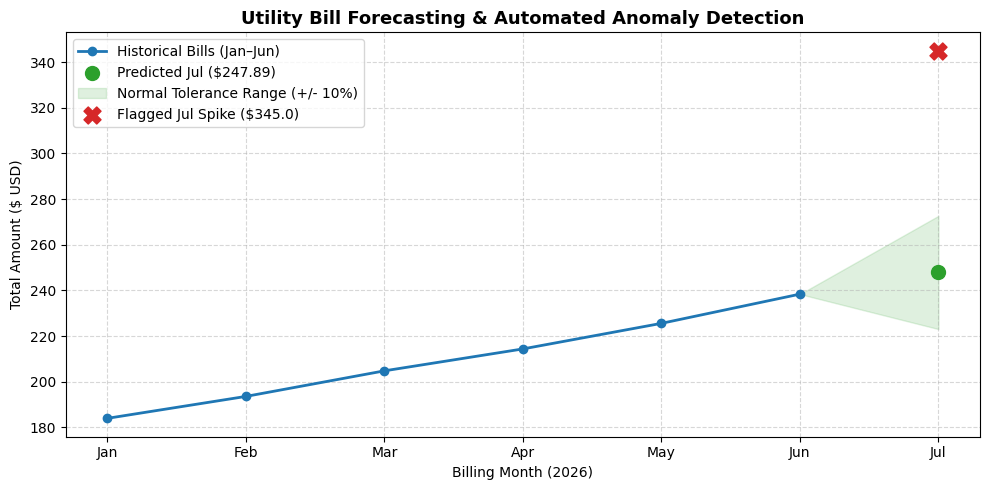

In [5]:
import matplotlib.pyplot as plt

# 1. TEST A NEW JULY BILL AGAINST YOUR FORECAST BOUNDS
july_actual_bill = {
    "billing_date": "2026-07-15",
    "usage_kwh": 2156.25,
    "rate_per_kwh": 0.16,
    "total_billed": 345.00  # Simulating an unexpected summer surge
}

lower_limit, upper_limit = forecast_output["expected_normal_range"]
predicted_val = forecast_output["predicted_bill_usd"]

# Automated Audit Check
if july_actual_bill["total_billed"] > upper_limit:
    status = f"FLAGGED: Actual (${july_actual_bill['total_billed']}) exceeds upper forecast bound (${upper_limit})"
else:
    status = "APPROVED: Within expected forecast range"

print("Audit Decision:", status)

# 2. PLOT HISTORICAL DATA, FORECAST & ANOMALY (Portfolio Visual)
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul"]
historical_bills = [r["total_billed"] for r in structured_records]

plt.figure(figsize=(10, 5))

# Plot Jan-Jun actual bills
plt.plot(months[:6], historical_bills, marker="o", color="#1f77b4", linewidth=2, label="Historical Bills (Jan–Jun)")

# Plot July predicted point & tolerance range
plt.scatter(["Jul"], [predicted_val], color="#2ca02c", s=100, zorder=5, label=f"Predicted Jul (${predicted_val})")
plt.fill_between(["Jun", "Jul"], [historical_bills[-1], lower_limit], [historical_bills[-1], upper_limit],
                 color="#2ca02c", alpha=0.15, label="Normal Tolerance Range (+/- 10%)")

# Plot July flagged anomaly
plt.scatter(["Jul"], [july_actual_bill["total_billed"]], color="#d62728", marker="X", s=150, zorder=6,
            label=f"Flagged Jul Spike (${july_actual_bill['total_billed']})")

plt.title("Utility Bill Forecasting & Automated Anomaly Detection", fontsize=13, fontweight="bold")
plt.xlabel("Billing Month (2026)")
plt.ylabel("Total Amount ($ USD)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()
